# `fig:axes` for the paper

Draws the two-row axes figure of the paper: **a)** gene axis, **b)** spot axis, at `CASE = lin_all`. The cascade down to the donor is that of `three_channels_analysis/canal_2/canal2_uncertainty_vs_error_classic.ipynb`, which is where the numbers themselves are read.
Output: `results/_analysis/figures_paper/`. The printed table and the degeneracy self-check come with it.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)
from src.evaluation.benchmark_summary import donor_lopo_stats

# =============================== SETTINGS ====================================
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
CANAL2      = "canal2_uncertainty"   # the model head itself (pred_var / dispersion)
LAMBDA_KEEP = 0.0                    # the Gaussians carry a beta-NLL sweep; 0.0 IS the true NLL

# ONE error case. Switch HERE, nothing else to change in the notebook.
#   lin_all   |y - mu|            over ALL the entries (zeros included)
#   lin_pos   |y - mu|            over y > 0
#   log_pos   |log y - log mu|    over y > 0
CASE = "lin_all"

# Five heads. The two CONSTRAINED-dispersion NB heads (per spot, per gene) are deliberately
# out of this figure: they only carry the parametrization argument, which has its own
# figure. The two _raw heads stay out too, their error lives on a different axis.
MODELS = ["homoscedastic", "heteroscedastic", "spot_homoscedastic",
          "poisson_cp", "negativebinomial_hetero_noanchor_cp"]

FIGDIR = PROJ / "results" / "_analysis" / "figures_paper"
# =============================================================================

N_PLUS_MIN = 60          # the script's inclusion filter, RE-APPLIED here: the parquets
                         # carry EVERY group present, filtering is the reader's job
CONVENTION = "v3_native_scale"
AXES = ["gene", "spot"]

# The group size depends on the case's POPULATION, not only on the axis.
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
# The descriptor that goes into the PRINTED caption.
CASE_FIG = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
            "lin_pos": "|y - mu|, detected entries only (y > 0)",
            "log_pos": "|log y - log mu|, detected entries only (y > 0)"}

# Canonical model -> color map, keyed on model_type.
MODEL_COLORS = {
    "homoscedastic":                        "#1f77b4",   # blue
    "heteroscedastic":                      "#ff7f0e",   # orange
    "spot_homoscedastic":                   "#2ca02c",   # green
    "poisson_cp":                           "#d62728",   # red
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",   # violet
}
MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

# On which axis each head is mute, and why. A mute head keeps its row in the
# figure: the absence of a filled marker IS the result, an omitted row would read as a
# missing data.
DEGENERATE_WHY = {
    "homoscedastic":                        ("gene", "one sigma^2 per GENE -> constant within a (gene,slide) pair"),
    "spot_homoscedastic":                   ("spot", "one sigma^2 per SPOT -> constant within a spot"),
    "poisson_cp":                           ("both", "u = mu exactly, no free parameter"),
    "heteroscedastic":                      (None,   "free variance per (spot, gene)"),
    "negativebinomial_hetero_noanchor_cp":  (None,   "free variance per (spot, gene)"),
}

# -- slide -> donor -----------------------------------------------------------------------
# SPLIT unit = donor, METRIC unit = slide (src/data/splitting.py).
DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())

def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}

# -- discovery ---------------------------------------------------------------------------
def canal2_runs(ds, models):
    base = RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS
    out = []
    if not base.is_dir():
        return out
    for model_dir in sorted(p for p in base.iterdir() if p.is_dir()):
        if model_dir.name not in models:
            continue
        for leaf in [model_dir] + sorted(model_dir.glob("lambda_*")):
            lam = leaf.name if leaf.name.startswith("lambda_") else None
            if lam is not None and LAMBDA_KEEP is not None:
                if not np.isclose(float(lam[len("lambda_"):]), LAMBDA_KEEP):
                    continue
            if (leaf / CANAL2 / "summary.json").is_file():
                out.append(dict(dataset=ds, model_type=model_dir.name, dir=leaf / CANAL2))
    return out

RUNS, stale = [], []
for ds in DATASETS:
    for r in canal2_runs(ds, MODELS):
        s = json.loads((r["dir"] / "summary.json").read_text())
        if s.get("not_applicable"):
            continue
        # GUARD: an artifact on the other column convention carries a converted scale. Mixing
        # it in silently is the one way to be wrong without noticing, so it is dropped by
        # name.
        if s.get("canal2_convention") != CONVENTION:
            stale.append((r["dataset"], r["model_type"], s.get("canal2_convention")))
            continue
        r["summary"] = s
        RUNS.append(r)

PAIR = {(r["dataset"], r["model_type"]): pd.read_parquet(r["dir"] / "pair_partial.parquet")
        for r in RUNS if (r["dir"] / "pair_partial.parquet").is_file()}
SPOT = {(r["dataset"], r["model_type"]): pd.read_parquet(r["dir"] / "spot_partial.parquet")
        for r in RUNS if (r["dir"] / "spot_partial.parquet").is_file()}
SUMM = {(r["dataset"], r["model_type"]): r["summary"] for r in RUNS}

print(f"canal2 = {CANAL2!r}   case = {CASE!r} ({CASE_FIG[CASE]})")
print(f"  under {RESULTS.relative_to(PROJ)}")
for ds in DATASETS:
    got = sorted(m for (d, m) in SUMM if d == ds)
    miss = [m for m in MODELS if m not in got]
    print(f"  {ds:<12s} {len(got):>2d}/{len(MODELS)} runs   missing: {miss if miss else '-'}")
if stale:
    print()
    print(f"(!) {len(stale)} run(s) NOT conforming to canal2_convention={CONVENTION!r} - DROPPED:")
    for ds, m, c in stale:
        print(f"    {ds:<12s} {m:<40s} convention read : {c!r}")
if CASE == "lin_all":
    print()
    print("WARNING, case lin_all: at y = 0 the absolute error IS |mu|, so the NAIVE value tends")
    print("to the uncertainty-mean coupling by construction, and the partial is ill-conditioned")
    print("there (r_Dm -> 1). This figure DEMONSTRATES the confound; it does not measure it.")

canal2 = 'canal2_uncertainty'   case = 'lin_all' (|y - mu|, all (spot, gene) entries, zeros included)
  under results
  10x_TuPro     5/5 runs   missing: -
  TLS           5/5 runs   missing: -
  LUNG_CANCER   5/5 runs   missing: -

WARNING, case lin_all: at y = 0 the absolute error IS |mu|, so the NAIVE value tends
to the uncertainty-mean coupling by construction, and the partial is ill-conditioned
there (r_Dm -> 1). This figure DEMONSTRATES the confound; it does not measure it.


## 1. The donor cascade, and the printed twin of the figure

Identical to the source notebook: the `n >= 60` filter, the group-size-weighted fold and the donor boundary are the script's. On the gene axis the fold is in two steps, groups to `(gene, donor)` weighted by size, then a simple mean over the donor's genes. On the spot axis a spot belongs to one slide hence one donor, and the mean is direct.

In [2]:
def donor_points(frame, ds, axis, stat):
    """{donor: value} + the number of groups kept, for ONE (axis, statistic).

    The n >= N_PLUS_MIN filter and the NaN removal happen HERE because the parquet carries
    EVERY group present."""
    col, ncol = f"{stat}_{CASE}", N_COL[CASE]
    if frame is None or col not in frame.columns or ncol not in frame.columns:
        return {}, 0
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return {}, 0
    s2d = slide_to_donor(ds)
    donor = d["slide"].map(lambda s: s2d.get(s, s))
    if axis == "spot":                       # one spot = one slide = one donor: plain mean
        return d.groupby(donor.to_numpy())[col].mean().to_dict(), int(len(d))
    g = pd.DataFrame({"gene": d["gene"].to_numpy(), "donor": donor.to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby(["gene", "donor"], as_index=False).sum()
    g["v"] = g["w"] / g["n"]                 # pair -> (gene, donor), weighted by n
    return g.groupby("donor")["v"].mean().to_dict(), int(len(d))


rows = []
for (ds, m) in SUMM:
    for axis in AXES:
        frame = (PAIR if axis == "gene" else SPOT).get((ds, m))
        rec = dict(dataset=ds, model=m, axis=axis)
        for stat, tag in (("r_uD", "naive"), ("r_partial", "partial")):
            pts, n = donor_points(frame, ds, axis, stat)
            if not pts:
                continue
            st = donor_lopo_stats(pts)
            rec.update({tag: st["mean"], f"{tag}_lo": st["ci95_mean"][0],
                        f"{tag}_hi": st["ci95_mean"][1], "K": st["K"], "n_groups": n})
        rows.append(rec)
RES = pd.DataFrame(rows)


def get(ds, m, axis):
    r = RES[(RES["dataset"] == ds) & (RES["model"] == m) & (RES["axis"] == axis)]
    return None if r.empty else r.iloc[0]


def cell(r, tag, width=26):
    """One table cell: the value, its CI, and '*' if the CI excludes zero."""
    if r is None or not np.isfinite(r.get(tag, np.nan)):
        return f"{'mute':>{width}s}"
    lo, hi = r.get(f"{tag}_lo", np.nan), r.get(f"{tag}_hi", np.nan)
    if not np.isfinite(lo):
        return f"{r[tag]:>+{width}.4f}"
    star = "*" if (lo > 0 or hi < 0) else " "
    return f"{r[tag]:+.4f} [{lo:+.4f},{hi:+.4f}]{star}".rjust(width)


print("#" * 134)
print(f"# CASE {CASE.upper()} - {CASE_FIG[CASE]}")
print("#" * 134)
for ds in DATASETS:
    sub = RES[RES["dataset"] == ds]
    if sub.empty:
        continue
    K = int(sub["K"].max()) if sub["K"].notna().any() else 0
    print()
    print(f"--- {DATASET_LABELS.get(ds, ds)}  (K = {K} donors) ---")
    print(f"  {'head':<40s} {'GENE AXIS naive':>26s} {'GENE AXIS control':>26s} "
          f"{'SPOT AXIS naive':>26s} {'SPOT AXIS control':>26s}")
    for m in MODELS:
        g, s = get(ds, m, "gene"), get(ds, m, "spot")
        if g is None and s is None:
            continue
        print(f"  {MODEL_LABELS.get(m, m):<40s} {cell(g,'naive')} {cell(g,'partial')} "
              f"{cell(s,'naive')} {cell(s,'partial')}")

print()
print("=" * 134)
print("THE DEGENERACY, PREDICTED THEN TESTED: a mute head is mute by construction, and the")
print("prediction comes from its parametrization, not from the data.")
print("=" * 134)
ok = bad = 0
for m in MODELS:
    dead, why = DEGENERATE_WHY[m]
    for axis in AXES:
        expect_mute = dead in (axis, "both")
        seen = [get(ds, m, axis) for ds in DATASETS]
        seen = [r for r in seen if r is not None]
        if not seen:
            continue
        is_mute = all(not np.isfinite(r.get("partial", np.nan)) for r in seen)
        flag = "OK " if is_mute == expect_mute else "(!)"
        ok, bad = (ok + 1, bad) if is_mute == expect_mute else (ok, bad + 1)
        print(f"  {flag} {MODEL_LABELS.get(m, m):<32s} axis {axis:<5s} "
              f"expected {'mute' if expect_mute else 'live':<7s} "
              f"read {'mute' if is_mute else 'live':<7s}  {why}")
print(f"  -> {ok} compliant, {bad} failed.")

######################################################################################################################################
# CASE LIN_ALL - |y - mu|, all (spot, gene) entries, zeros included
######################################################################################################################################

--- Tumor Profiler  (K = 7 donors) ---
  head                                                GENE AXIS naive          GENE AXIS control            SPOT AXIS naive          SPOT AXIS control
  Gaussian gene-homoscedastic                                    mute                       mute +0.3418 [+0.0554,+0.6281]* -0.0209 [-0.0759,+0.0341] 
  Gaussian heteroscedastic                 +0.1973 [+0.1759,+0.2187]* +0.0578 [+0.0395,+0.0761]* +0.6640 [+0.6208,+0.7072]* +0.1461 [+0.1139,+0.1783]*
  Gaussian spot-homoscedastic              +0.0572 [+0.0183,+0.0961]* +0.0579 [+0.0430,+0.0728]*                       mute                       mute
  Poisson         

## 2. The paper figure — 2 axes x 3 cohorts, both legends on the LEFT

Two rows, the two groupings; three columns, the three cohorts. Inside a panel, one row per head: **hollow** marker = naive value, **filled** marker = controlled value with its Student-t interval over donors. The horizontal gap between the two IS the effect of the confounder.

Scales are shared by ROW, not by figure: the gene axis and the spot axis do not span the same range, and forcing a common scale would crush one of them.

The three knobs: `ROW_H` (height per row), `LEGEND_FS`, `LEGEND_GUTTER`.

legend strip = 0.211 of the width -> 2.23 in per panel


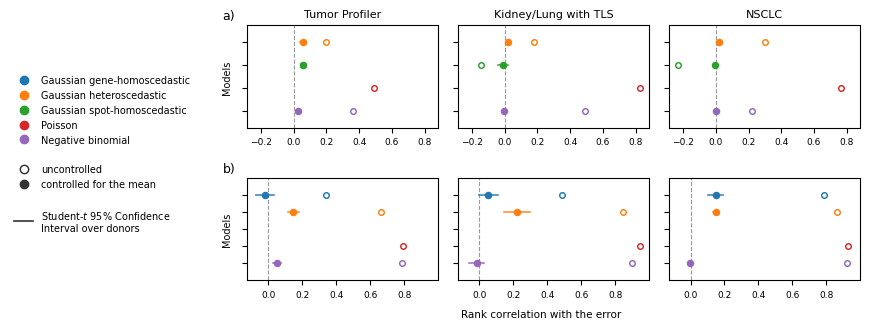

## FIGURE  fig_canal2_axes_paper_lin_all_pr_classic3_canal2_uncertainty.pdf
## TITLE   Predicted uncertainty against prediction error, on both groupings, before and after controlling for the predicted mean
## CAPTION One row per predictive head within a panel, color identifying the head. Hollow marker: the
## CAPTION Spearman correlation between the predicted uncertainty and the error inside the group, with
## CAPTION no adjustment. Filled marker: the partial correlation, the predicted mean being partialled
## CAPTION out as a rank covariate. The horizontal gap between the two IS the effect of the confounder.
## CAPTION Bar: Student-t 95% interval over the 8 held-out donors, drawn on the
## CAPTION controlled value only, the uncontrolled one being a starting point of the argument and never
## CAPTION a measurement.
## CAPTION Error definition: |y - mu|, all (spot, gene) entries, zeros included.
## CAPTION a) one group per gene and slide, ranking the error across the spots of that gene.

In [3]:
from matplotlib.lines import Line2D

FIGDIR.mkdir(parents=True, exist_ok=True)

def fig_show(fig, stem, title, caption):
    """Save .pdf + .png, show, then PRINT the title and caption."""
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


AXIS_GROUPING = {
    "gene": "one group per gene and slide, ranking the error across the spots of that gene",
    "spot": "one group per slide and spot, ranking the error across the genes of that spot",
}

COL_W         = 2.9     # width per cohort
ROW_H         = 1.6     # height per row
LEGEND_FS     = 7
LEGEND_GUTTER = 0.02    # white space between the legend strip and the axis labels
BOTTOM_PAD    = 0.0    # strip reserved at the bottom for the SHARED axis label

drawn = []
fig, axes = plt.subplots(len(AXES), len(DATASETS),
                         figsize=(COL_W * len(DATASETS), ROW_H * len(AXES)), sharex="row")
axes = np.atleast_2d(axes)
for i, axis in enumerate(AXES):
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        # EVERY head keeps its row, even a mute one, and there are TWO ways to be mute:
        #   no marker           variance CONSTANT within the group -> no correlation.
        #   hollow, no filled   variance monotone in mu (Poisson) -> the partial does not exist.
        for y, m in enumerate(MODELS):
            r = get(ds, m, axis)
            if r is None:
                continue
            c = MODEL_COLORS.get(m, "0.4")
            nv, pv = r.get("naive", np.nan), r.get("partial", np.nan)
            if np.isfinite(nv):
                ax.plot([nv], [y], "o", ms=4.0, mfc="none", mec=c, mew=1.05, zorder=3)
            lo, hi = r.get("partial_lo", np.nan), r.get("partial_hi", np.nan)
            if np.isfinite(pv):
                if np.isfinite(lo):
                    ax.plot([lo, hi], [y, y], color=c, lw=1.2, alpha=0.85, zorder=3)
                ax.plot([pv], [y], "o", ms=4.4, color=c, zorder=4)
            drawn.append(dict(axis=axis, dataset=ds, model=m,
                              naive=nv, partial=pv, lo=lo, hi=hi))
        ax.axvline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
        ax.set_yticks(range(len(MODELS)))
        ax.set_yticklabels([])          # one tick per HEAD; the COLOR identifies it
        if j == 0:
            ax.set_ylabel("Models", fontsize=7)
            ax.text(-0.06, 1.03, f"{'ab'[i]})", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=9)
        ax.invert_yaxis()
        ax.tick_params(axis="x", labelsize=6.5)
        ax.margins(y=0.25)
        if i == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
        # NO per-panel set_xlabel: the text is wider than a column, so three copies would
        # overlap. One single label, placed under the grid, further down.

model_handles = [Line2D([], [], marker="o", ls="", color=MODEL_COLORS.get(m, "0.4"),
                        label=MODEL_LABELS.get(m, m)) for m in MODELS]
spacer, spacer2 = (Line2D([], [], ls="", marker="", label="") for _ in range(2))
# SHORT labels: they were what set the strip width, hence the panels. The full sentence
# ('partial correlation, controlled for the predicted mean') lives in the printed caption.
cond_handles = [Line2D([], [], marker="o", ls="", mfc="none", mec="#333333", mew=1.05,
                       label="uncontrolled"),
                Line2D([], [], marker="o", ls="", color="#333333",
                       label="controlled for the mean")]
# The horizontal BAR is the one drawn element the figure would otherwise not explain (only
# the printed caption states it). A neutral line with no marker, like the two entries
# above: here the entry designates a LINE, not a point.
bar_handle = [Line2D([], [], color="#333333", lw=1.2, marker="",
                     label="Student-$t$ 95% Confidence \nInterval over donors")]

leg = fig.legend(handles=model_handles + [spacer] + cond_handles + [spacer2] + bar_handle,
                 loc="center left",
                 bbox_to_anchor=(0.0, 0.5), ncol=1, frameon=False, fontsize=LEGEND_FS)
fig.canvas.draw()
legend_w = leg.get_window_extent().width / fig.bbox.width
left = legend_w + LEGEND_GUTTER
fig.tight_layout(rect=(left, BOTTOM_PAD, 1, 1))
# The shared axis label, centered on the GRID (not on the figure: the legend strip would
# shift a fig.supxlabel to the left).
fig.text((left + 1) / 2, BOTTOM_PAD / 2, "Rank correlation with the error",
         ha="center", va="center", fontsize=7.5)
print(f"legend strip = {legend_w:.3f} of the width -> "
      f"{COL_W * len(DATASETS) * (1 - left) / len(DATASETS):.2f} in per panel")

caption = [
    "One row per predictive head within a panel, color identifying the head. Hollow marker: the",
    "Spearman correlation between the predicted uncertainty and the error inside the group, with",
    "no adjustment. Filled marker: the partial correlation, the predicted mean being partialled",
    "out as a rank covariate. The horizontal gap between the two IS the effect of the confounder.",
    f"Bar: Student-t 95% interval over the {int(RES['K'].max())} held-out donors, drawn on the",
    "controlled value only, the uncontrolled one being a starting point of the argument and never",
    "a measurement.",
    f"Error definition: {CASE_FIG[CASE]}.",
]
for q, axis in enumerate(AXES):
    caption.append(f"{'ab'[q]}) {AXIS_GROUPING[axis]}.")
caption += [
    "Rows are not drawn on a shared horizontal scale: the two groupings are duals and a head",
    "silent on one is measurable on the other.",
    "A head that is incomplete on a row is MUTE there BY CONSTRUCTION and not missing, and the two",
    "ways of being mute are distinguishable. No marker at all: the predicted spread is constant",
    "inside the group, so no rank correlation exists. Hollow marker but no filled one: the spread",
    "varies but is a monotone function of the predicted mean, so the correlation exists and the",
    "partial correlation does not.",
]

fig_show(fig, FIGDIR / f"fig_canal2_axes_paper_{CASE}_{RUN_ID}_{CANAL2}",
         "Predicted uncertainty against prediction error, on both groupings, before and after "
         "controlling for the predicted mean",
         caption)

DRAWN = pd.DataFrame(drawn) if drawn else pd.DataFrame()
print()
print("=" * 126)
print("THE PRINTED TWIN OF THE FIGURE - exactly the plotted values, nothing more")
print("=" * 126)
for axis in AXES:
    sub = DRAWN[DRAWN["axis"] == axis] if not DRAWN.empty else DRAWN
    if sub.empty:
        continue
    print()
    print(f"[axis {axis} | {CASE}]")
    print(f"    {'cohort':<22s} {'head':<32s} {'naive':>9s} {'control':>9s} {'95% CI':>22s}")
    for _, r in sub.iterrows():
        ci = f"[{r['lo']:+.4f}, {r['hi']:+.4f}]" if np.isfinite(r["lo"]) else "n/a"
        nv = f"{r['naive']:+.4f}" if np.isfinite(r["naive"]) else "     n/a"
        pv = f"{r['partial']:+.4f}" if np.isfinite(r["partial"]) else "    mute"
        print(f"    {DATASET_LABELS.get(r['dataset'], r['dataset']):<22s} "
              f"{MODEL_LABELS.get(r['model'], r['model']):<32s} {nv:>9s} {pv:>9s} {ci:>22s}")